# Comparative Analysis of Seven Models for Oral Disease Image Classification

This notebook presents a comparative evaluation of seven machine learning and deep learning models for multiclass oral disease image classification.

### Models Evaluated

#### Image-based Deep Learning Models
1. Custom CNN
2. MobileNetV2
3. EfficientNetB0
4. LeNet-style CNN

#### HOG Feature-based Models
5. Linear SVM
6. Random Forest
7. Artificial Neural Network (ANN)

All models are evaluated using the same stratified training, validation, and test partitions. Performance is compared using Accuracy, Balanced Accuracy, Macro Precision, Macro Recall, Macro F1-score, Weighted F1-score, and training time.

MobileNetV2 and EfficientNetB0 are trained with `weights=None`, ensuring that all experiments are self-contained and do not depend on externally downloaded pretrained weights.


## 1. Imports and reproducibility

In [4]:
import os
import gc
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import joblib

from skimage.color import rgb2gray
from skimage.feature import hog
from skimage.transform import resize

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 2. Experimental Configuration

In [5]:
IMG_SIZE = (128, 128)
HOG_SIZE = (128, 128)

BATCH_SIZE = 32

MAX_EPOCHS = 8
EARLY_STOP_PATIENCE = 2
LEARNING_RATE = 3e-4

TEST_SIZE = 0.15
VAL_SIZE_FROM_REMAINING = 0.1765

PRETRAINED_WEIGHTS = None

HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (16, 16)
HOG_CELLS_PER_BLOCK = (2, 2)

FAST_RUN = False
MAX_IMAGES_PER_CLASS_FAST = 100

AUTOTUNE = tf.data.AUTOTUNE

OUTPUT_DIR = Path("/kaggle/working/oral_7_model_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("MAX_EPOCHS:", MAX_EPOCHS)
print("OUTPUT_DIR:", OUTPUT_DIR)

MAX_EPOCHS: 8
OUTPUT_DIR: /kaggle/working/oral_7_model_results


## 3. Locate the Kaggle dataset

In [6]:
KAGGLE_INPUT = Path("/kaggle/input")

EXPECTED_CLASSES = {
    "Calculus",
    "Hypodontia",
    "Mouth ulcer",
    "Normal",
    "caries",
    "tooth discoloration",
}

confirmed_path = Path(
    "/kaggle/input/datasets/jhirshaikh/oral-image-dataset/oral dataset"
)

DATA_DIR = confirmed_path if confirmed_path.exists() else None

if DATA_DIR is None:
    for folder in KAGGLE_INPUT.rglob("*"):
        if not folder.is_dir():
            continue

        try:
            child_dirs = {p.name for p in folder.iterdir() if p.is_dir()}
        except Exception:
            continue

        if EXPECTED_CLASSES.issubset(child_dirs):
            DATA_DIR = folder
            break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate the oral image dataset. "
        "Attach jhirshaikh/oral-image-dataset to the Kaggle notebook."
    )

print("Dataset directory:", DATA_DIR)

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        print(" -", folder.name)

Dataset directory: /kaggle/input/datasets/jhirshaikh/oral-image-dataset/oral dataset
 - Calculus
 - Hypodontia
 - Mouth ulcer
 - Normal
 - caries
 - tooth discoloration


## 4. Build the image dataframe

In [7]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for class_dir in sorted([p for p in DATA_DIR.iterdir() if p.is_dir()]):
    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(image_path),
                "label": class_dir.name,
            })

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError("No images were found.")

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Total images:", len(df))
display(df.head())

Total images: 4375


,filepath,label
0,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Normal
1,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Calculus
2,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Mouth ulcer
3,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Calculus
4,/kaggle/input/datasets/jhirshaikh/oral-image-d...,tooth discoloration


## 5. Class distribution

,Image Count
label,
Calculus,1296
Hypodontia,1251
Mouth ulcer,265
Normal,286
caries,219
tooth discoloration,1058


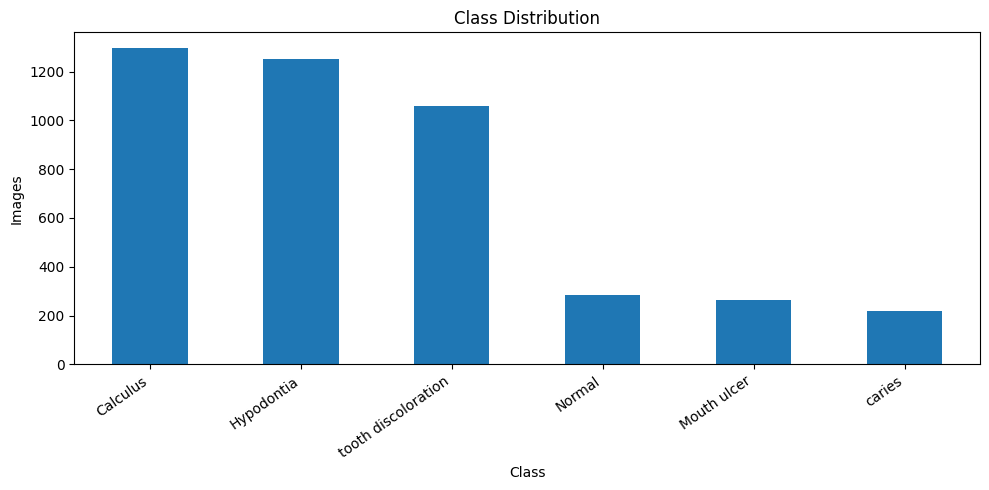

In [8]:
class_counts = df["label"].value_counts().sort_index()
display(class_counts.rename("Image Count").to_frame())

plt.figure(figsize=(10, 5))
class_counts.sort_values(ascending=False).plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Optional fast-run mode

In [9]:
if FAST_RUN:
    df = (
        df.groupby("label", group_keys=False)
        .apply(
            lambda x: x.sample(
                min(len(x), MAX_IMAGES_PER_CLASS_FAST),
                random_state=SEED,
            )
        )
        .reset_index(drop=True)
    )
    print("FAST_RUN enabled.")
else:
    print("Using full dataset.")

Using full dataset.


## 7. Encode labels

In [10]:
class_names = sorted(df["label"].unique())
class_to_index = {name: idx for idx, name in enumerate(class_names)}
index_to_class = {idx: name for name, idx in class_to_index.items()}

df["label_id"] = df["label"].map(class_to_index)

NUM_CLASSES = len(class_names)

class_mapping_df = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": [index_to_class[i] for i in range(NUM_CLASSES)],
})

display(class_mapping_df)

class_mapping_df.to_csv(
    OUTPUT_DIR / "class_mapping.csv",
    index=False,
)

,class_id,class_name
0,0,Calculus
1,1,Hypodontia
2,2,Mouth ulcer
3,3,Normal
4,4,caries
5,5,tooth discoloration


## 8. Stratified train / validation / test split

In [11]:
train_val_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df["label_id"],
    random_state=SEED,
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=VAL_SIZE_FROM_REMAINING,
    stratify=train_val_df["label_id"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train:      {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test:       {len(test_df)} ({len(test_df)/len(df):.1%})")

split_summary = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts(),
}).fillna(0).astype(int).sort_index()

display(split_summary)

Train:      3061 (70.0%)
Validation: 657 (15.0%)
Test:       657 (15.0%)


,Train,Validation,Test
label,,,
Calculus,908,194,194
Hypodontia,875,188,188
Mouth ulcer,185,40,40
Normal,200,43,43
caries,153,33,33
tooth discoloration,740,159,159


## 9. Class weights

In [12]:
classes = np.arange(NUM_CLASSES)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_id"].to_numpy(),
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

display(
    pd.DataFrame({
        "Class": [index_to_class[i] for i in classes],
        "Weight": [class_weights[i] for i in classes],
    })
)

,Class,Weight
0,Calculus,0.561858
1,Hypodontia,0.583048
2,Mouth ulcer,2.757658
3,Normal,2.550833
4,caries,3.334423
5,tooth discoloration,0.689414


## 10. TensorFlow image pipeline

In [13]:
def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE,
    )

    image = tf.cast(image, tf.float32)

    return image, label


def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].astype(str).to_numpy()
    labels = dataframe["label_id"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE,
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print(train_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


## 11. Shared augmentation

In [14]:
def build_augmentation():
    return keras.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.06),
            layers.RandomZoom(0.08),
            layers.RandomContrast(0.08),
        ],
        name="augmentation",
    )

# Part A — Image-Based Deep Learning Models

The following four architectures are trained directly on resized RGB images.

## 12. Custom CNN

In [15]:
def build_custom_cnn():
    inputs = keras.Input(
        shape=IMG_SIZE + (3,),
        name="image",
    )

    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    for filters in [32, 64, 128]:
        x = layers.Conv2D(
            filters,
            3,
            padding="same",
            activation="relu",
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        192,
        3,
        padding="same",
        activation="relu",
    )(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu",
    )(x)

    x = layers.Dropout(0.35)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="Custom_CNN",
    )

## 13. LeNet-style CNN

In [16]:
def build_lenet():
    inputs = keras.Input(
        shape=IMG_SIZE + (3,),
        name="image",
    )

    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    x = layers.Conv2D(
        16,
        5,
        activation="relu",
        padding="same",
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        32,
        5,
        activation="relu",
        padding="same",
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same",
    )(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        64,
        activation="relu",
    )(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="LeNet_Style_CNN",
    )

## 14. MobileNetV2 and EfficientNetB0

In [17]:
def build_application_model(model_name):

    if model_name == "MobileNetV2":
        backbone = keras.applications.MobileNetV2(
            include_top=False,
            weights=PRETRAINED_WEIGHTS,
            input_shape=IMG_SIZE + (3,),
            alpha=0.75,
        )

        preprocess_fn = keras.applications.mobilenet_v2.preprocess_input

    elif model_name == "EfficientNetB0":
        backbone = keras.applications.EfficientNetB0(
            include_top=False,
            weights=PRETRAINED_WEIGHTS,
            input_shape=IMG_SIZE + (3,),
        )

        preprocess_fn = keras.applications.efficientnet.preprocess_input

    else:
        raise ValueError(model_name)

    backbone.trainable = True

    inputs = keras.Input(
        shape=IMG_SIZE + (3,),
        name="image",
    )

    x = build_augmentation()(inputs)
    x = preprocess_fn(x)

    x = backbone(
        x,
        training=True,
    )

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name=model_name,
    )

## 15. Shared evaluation helpers

In [18]:
def compute_metrics(y_true, y_pred):
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_p,
        "Weighted Recall": weighted_r,
        "Weighted F1": weighted_f1,
    }


def evaluate_predictions(
    model_name,
    y_true,
    y_pred,
    training_time_min,
    model_type,
):
    metrics = compute_metrics(
        y_true,
        y_pred,
    )

    return {
        "Model": model_name,
        "Type": model_type,
        **{k: float(v) for k, v in metrics.items()},
        "Training Time (min)": float(training_time_min),
    }

## 16. Train one deep-learning model

In [19]:
def train_deep_model(model_name):
    print("\n" + "=" * 80)
    print("TRAINING:", model_name)
    print("=" * 80)

    keras.backend.clear_session()
    gc.collect()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    if model_name == "Custom CNN":
        model = build_custom_cnn()

    elif model_name == "LeNet-style CNN":
        model = build_lenet()

    else:
        model = build_application_model(
            model_name
        )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    checkpoint_path = OUTPUT_DIR / f"{slug}_best.keras"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOP_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=1e-6,
            verbose=1,
        ),
    ]

    start = time.perf_counter()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1,
    )

    training_time_min = (time.perf_counter() - start) / 60.0

    pd.DataFrame(history.history).to_csv(
        OUTPUT_DIR / f"{slug}_history.csv",
        index=False,
    )

    best_model = keras.models.load_model(
        checkpoint_path
    )

    val_probs = best_model.predict(
        val_ds,
        verbose=0,
    )
    val_pred = val_probs.argmax(axis=1)
    val_true = val_df["label_id"].to_numpy()

    val_metrics = compute_metrics(
        val_true,
        val_pred,
    )

    test_probs = best_model.predict(
        test_ds,
        verbose=0,
    )
    test_pred = test_probs.argmax(axis=1)
    test_true = test_df["label_id"].to_numpy()

    result = evaluate_predictions(
        model_name=model_name,
        y_true=test_true,
        y_pred=test_pred,
        training_time_min=training_time_min,
        model_type="Deep Learning",
    )

    result["Validation Macro F1"] = float(
        val_metrics["Macro F1"]
    )
    result["Parameters"] = int(
        best_model.count_params()
    )

    report_df = pd.DataFrame(
        classification_report(
            test_true,
            test_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0,
        )
    ).T

    report_df.to_csv(
        OUTPUT_DIR / f"{slug}_classification_report.csv"
    )

    cm = confusion_matrix(
        test_true,
        test_pred,
    )

    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names,
    ).to_csv(
        OUTPUT_DIR / f"{slug}_confusion_matrix.csv"
    )

    return result

## 17. Train the four image-based models

In [20]:
deep_model_names = [
    "Custom CNN",
    "LeNet-style CNN",
    "MobileNetV2",
    "EfficientNetB0",
]

all_results = []

for model_name in deep_model_names:
    result = train_deep_model(
        model_name
    )

    all_results.append(result)

deep_results_df = pd.DataFrame(
    all_results
)

display(deep_results_df)


TRAINING: Custom CNN
Epoch 1/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3546 - loss: 1.5885
Epoch 1: val_loss improved from None to 2.43209, saving model to /kaggle/working/oral_7_model_results/custom_cnn_best.keras

Epoch 1: finished saving model to /kaggle/working/oral_7_model_results/custom_cnn_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - accuracy: 0.4289 - loss: 1.4752 - val_accuracy: 0.0670 - val_loss: 2.4321 - learning_rate: 3.0000e-04
Epoch 2/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 986ms/step - accuracy: 0.5370 - loss: 1.2541
Epoch 2: val_loss did not improve from 2.43209

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
96/96 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.5599 - loss: 1.2366 - val_accuracy: 0.0609 - val_loss: 3.3558 - learning_rate: 3.0000e-04
Epoch 3/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 986ms/step - accuracy: 0.6320 - loss: 1.0909
Epoch 3: val_loss did not improve from 2.43209

Epoch 3: ReduceLROnPlateau reducing learning rat

,Model,Type,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Training Time (min),Validation Macro F1,Parameters
0,Custom CNN,Deep Learning,0.066971,0.170833,0.044325,0.170833,0.028031,0.016493,0.066971,0.010805,5.169664,0.022618,340998
1,LeNet-style CNN,Deep Learning,0.298326,0.267204,0.420400,0.267204,0.198407,0.442086,0.298326,0.263525,5.439112,0.199488,37094
2,MobileNetV2,Deep Learning,0.050228,0.166667,0.008371,0.166667,0.015942,0.002523,0.050228,0.004804,5.119774,0.015942,1389750
3,EfficientNetB0,Deep Learning,0.065449,0.166667,0.010908,0.166667,0.020476,0.004284,0.065449,0.008041,9.077933,0.020476,4057257


# Part B — HOG Feature Extraction

Histogram of Oriented Gradients (HOG) features are extracted from the images and used as input to Linear SVM, Random Forest, and ANN.

## 18. HOG feature extractor

In [21]:
def extract_hog_from_path(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        image = np.asarray(img)

    image = resize(
        image,
        HOG_SIZE,
        anti_aliasing=True,
    )

    gray = rgb2gray(image)

    features = hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        feature_vector=True,
    )

    return features.astype(np.float32)


def extract_hog_matrix(dataframe, name):
    print(f"Extracting HOG: {name}")

    feature_list = []

    start = time.perf_counter()

    for i, path in enumerate(
        dataframe["filepath"].tolist(),
        start=1,
    ):
        feature_list.append(
            extract_hog_from_path(path)
        )

        if i % 500 == 0:
            print(
                f"  processed {i}/{len(dataframe)}"
            )

    X = np.stack(feature_list)

    elapsed = time.perf_counter() - start

    print(
        f"{name}: {X.shape}, "
        f"time={elapsed/60:.2f} min"
    )

    return X

## 19. Extract HOG features once

In [22]:
X_train_hog = extract_hog_matrix(
    train_df,
    "Train",
)

X_val_hog = extract_hog_matrix(
    val_df,
    "Validation",
)

X_test_hog = extract_hog_matrix(
    test_df,
    "Test",
)

y_train = train_df["label_id"].to_numpy()
y_val = val_df["label_id"].to_numpy()
y_test = test_df["label_id"].to_numpy()

print("HOG feature dimension:", X_train_hog.shape[1])

Extracting HOG: Train
  processed 500/3061
  processed 1000/3061
  processed 1500/3061
  processed 2000/3061
  processed 2500/3061
  processed 3000/3061
Train: (3061, 1764), time=11.49 min
Extracting HOG: Validation
  processed 500/657
Validation: (657, 1764), time=1.94 min
Extracting HOG: Test
  processed 500/657
Test: (657, 1764), time=2.43 min
HOG feature dimension: 1764


## 20. Linear SVM

In [23]:
print("=" * 80)
print("TRAINING: Linear SVM")
print("=" * 80)

svm_model = Pipeline(
    [
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "svm",
            LinearSVC(
                class_weight="balanced",
                random_state=SEED,
                dual="auto",
                max_iter=5000,
            ),
        ),
    ]
)

start = time.perf_counter()

svm_model.fit(
    X_train_hog,
    y_train,
)

svm_time_min = (
    time.perf_counter() - start
) / 60.0

svm_val_pred = svm_model.predict(
    X_val_hog
)

svm_test_pred = svm_model.predict(
    X_test_hog
)

svm_val_metrics = compute_metrics(
    y_val,
    svm_val_pred,
)

svm_result = evaluate_predictions(
    model_name="Linear SVM",
    y_true=y_test,
    y_pred=svm_test_pred,
    training_time_min=svm_time_min,
    model_type="HOG + Classical ML",
)

svm_result["Validation Macro F1"] = float(
    svm_val_metrics["Macro F1"]
)

svm_result["Parameters"] = np.nan

all_results.append(
    svm_result
)

joblib.dump(
    svm_model,
    OUTPUT_DIR / "linear_svm.joblib",
)

print(svm_result)

TRAINING: Linear SVM
{'Model': 'Linear SVM', 'Type': 'HOG + Classical ML', 'Accuracy': 0.7123287671232876, 'Balanced Accuracy': 0.5788391116145186, 'Macro Precision': 0.5862226916090906, 'Macro Recall': 0.5788391116145186, 'Macro F1': 0.579598894460691, 'Weighted Precision': 0.7171926967700561, 'Weighted Recall': 0.7123287671232876, 'Weighted F1': 0.7133533741330612, 'Training Time (min)': 13.524751969916663, 'Validation Macro F1': 0.5693875186134479, 'Parameters': nan}


## 21. Random Forest

In [24]:
print("=" * 80)
print("TRAINING: Random Forest")
print("=" * 80)

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=None,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)

start = time.perf_counter()

rf_model.fit(
    X_train_hog,
    y_train,
)

rf_time_min = (
    time.perf_counter() - start
) / 60.0

rf_val_pred = rf_model.predict(
    X_val_hog
)

rf_test_pred = rf_model.predict(
    X_test_hog
)

rf_val_metrics = compute_metrics(
    y_val,
    rf_val_pred,
)

rf_result = evaluate_predictions(
    model_name="Random Forest",
    y_true=y_test,
    y_pred=rf_test_pred,
    training_time_min=rf_time_min,
    model_type="HOG + Classical ML",
)

rf_result["Validation Macro F1"] = float(
    rf_val_metrics["Macro F1"]
)

rf_result["Parameters"] = np.nan

all_results.append(
    rf_result
)

joblib.dump(
    rf_model,
    OUTPUT_DIR / "random_forest.joblib",
)

print(rf_result)

TRAINING: Random Forest
{'Model': 'Random Forest', 'Type': 'HOG + Classical ML', 'Accuracy': 0.7792998477929984, 'Balanced Accuracy': 0.5847633306682997, 'Macro Precision': 0.7653138542852224, 'Macro Recall': 0.5847633306682997, 'Macro F1': 0.6204006641941041, 'Weighted Precision': 0.7792016184969308, 'Weighted Recall': 0.7792998477929984, 'Weighted F1': 0.7574337474959625, 'Training Time (min)': 0.15182968490000046, 'Validation Macro F1': 0.6161464250111569, 'Parameters': nan}


## 22. HOG-based ANN / MLP

In [25]:
hog_scaler = StandardScaler()

X_train_ann = hog_scaler.fit_transform(
    X_train_hog
).astype(np.float32)

X_val_ann = hog_scaler.transform(
    X_val_hog
).astype(np.float32)

X_test_ann = hog_scaler.transform(
    X_test_hog
).astype(np.float32)

joblib.dump(
    hog_scaler,
    OUTPUT_DIR / "hog_ann_scaler.joblib",
)

keras.backend.clear_session()

ann_model = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_ann.shape[1],)
        ),

        layers.Dense(
            256,
            activation="relu",
        ),

        layers.BatchNormalization(),

        layers.Dropout(0.30),

        layers.Dense(
            128,
            activation="relu",
        ),

        layers.Dropout(0.25),

        layers.Dense(
            NUM_CLASSES,
            activation="softmax",
        ),
    ],
    name="HOG_ANN",
)

ann_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ann_checkpoint = (
    OUTPUT_DIR / "hog_ann_best.keras"
)

ann_callbacks = [
    keras.callbacks.ModelCheckpoint(
        ann_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1,
    ),
]

start = time.perf_counter()

ann_history = ann_model.fit(
    X_train_ann,
    y_train,
    validation_data=(
        X_val_ann,
        y_val,
    ),
    epochs=10,
    batch_size=64,
    class_weight=class_weights,
    callbacks=ann_callbacks,
    verbose=1,
)

ann_time_min = (
    time.perf_counter() - start
) / 60.0

ann_model = keras.models.load_model(
    ann_checkpoint
)

ann_val_probs = ann_model.predict(
    X_val_ann,
    verbose=0,
)

ann_val_pred = ann_val_probs.argmax(
    axis=1
)

ann_test_probs = ann_model.predict(
    X_test_ann,
    verbose=0,
)

ann_test_pred = ann_test_probs.argmax(
    axis=1
)

ann_val_metrics = compute_metrics(
    y_val,
    ann_val_pred,
)

ann_result = evaluate_predictions(
    model_name="ANN (HOG)",
    y_true=y_test,
    y_pred=ann_test_pred,
    training_time_min=ann_time_min,
    model_type="HOG + Neural Network",
)

ann_result["Validation Macro F1"] = float(
    ann_val_metrics["Macro F1"]
)

ann_result["Parameters"] = int(
    ann_model.count_params()
)

all_results.append(
    ann_result
)

print(ann_result)

Epoch 1/10
43/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3448 - loss: 2.1252
Epoch 1: val_loss improved from None to 0.93458, saving model to /kaggle/working/oral_7_model_results/hog_ann_best.keras

Epoch 1: finished saving model to /kaggle/working/oral_7_model_results/hog_ann_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.4665 - loss: 1.6683 - val_accuracy: 0.6712 - val_loss: 0.9346
Epoch 2/10
45/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6869 - loss: 0.8618
Epoch 2: val_loss improved from 0.93458 to 0.77820, saving model to /kaggle/working/oral_7_model_results/hog_ann_best.keras

Epoch 2: finished saving model to /kaggle/working/oral_7_model_results/hog_ann_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6949 - loss: 0.8334 - val_accuracy: 0.7260 - val_loss: 0.7782
Epoch 3/10
42/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7833 - loss: 0.5784
Epoch 3: val_loss improved from 0.77820 to 0.70809, saving model to /kaggle/working/oral_

# Part C — Seven-Model Comparison

## 23. Final comparison table

In [26]:
results_df = pd.DataFrame(
    all_results
)

comparison_columns = [
    "Model",
    "Type",
    "Validation Macro F1",
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Training Time (min)",
    "Parameters",
]

comparison_df = (
    results_df[comparison_columns]
    .sort_values(
        "Validation Macro F1",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(comparison_df)

comparison_df.to_csv(
    OUTPUT_DIR / "seven_model_comparison.csv",
    index=False,
)

,Model,Type,Validation Macro F1,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (min),Parameters
0,ANN (HOG),HOG + Neural Network,0.694257,0.785388,0.704776,0.686281,0.704776,0.693617,0.786416,0.091274,486534.0
1,Random Forest,HOG + Classical ML,0.616146,0.779300,0.584763,0.765314,0.584763,0.620401,0.757434,0.151830,NaN
2,Linear SVM,HOG + Classical ML,0.569388,0.712329,0.578839,0.586223,0.578839,0.579599,0.713353,13.524752,NaN
3,LeNet-style CNN,Deep Learning,0.199488,0.298326,0.267204,0.420400,0.267204,0.198407,0.263525,5.439112,37094.0
4,Custom CNN,Deep Learning,0.022618,0.066971,0.170833,0.044325,0.170833,0.028031,0.010805,5.169664,340998.0
5,EfficientNetB0,Deep Learning,0.020476,0.065449,0.166667,0.010908,0.166667,0.020476,0.008041,9.077933,4057257.0
6,MobileNetV2,Deep Learning,0.015942,0.050228,0.166667,0.008371,0.166667,0.015942,0.004804,5.119774,1389750.0


## 24. Select best model by validation Macro-F1

In [27]:
best_row = comparison_df.iloc[0]

print("Best model by Validation Macro-F1")
print("---------------------------------")
print("Model:", best_row["Model"])
print(
    "Validation Macro-F1:",
    f"{best_row['Validation Macro F1']:.4f}",
)
print(
    "Test Macro-F1:",
    f"{best_row['Macro F1']:.4f}",
)
print(
    "Test Accuracy:",
    f"{best_row['Accuracy']:.4f}",
)

Best model by Validation Macro-F1
---------------------------------
Model: ANN (HOG)
Validation Macro-F1: 0.6943
Test Macro-F1: 0.6936
Test Accuracy: 0.7854


## 25. Accuracy comparison

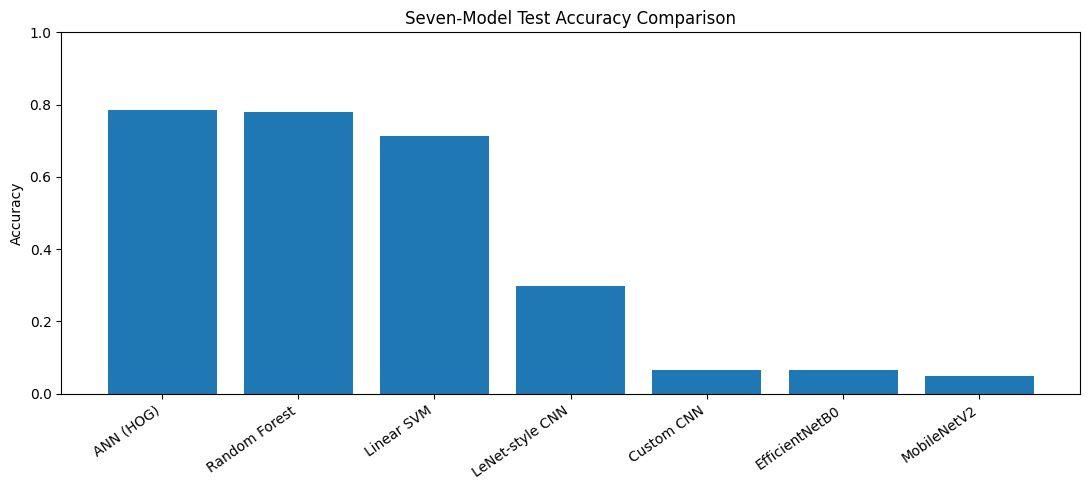

In [28]:
plot_df = comparison_df.sort_values(
    "Accuracy",
    ascending=False,
)

plt.figure(figsize=(11, 5))
plt.bar(
    plot_df["Model"],
    plot_df["Accuracy"],
)
plt.title("Seven-Model Test Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 26. Macro-F1 comparison

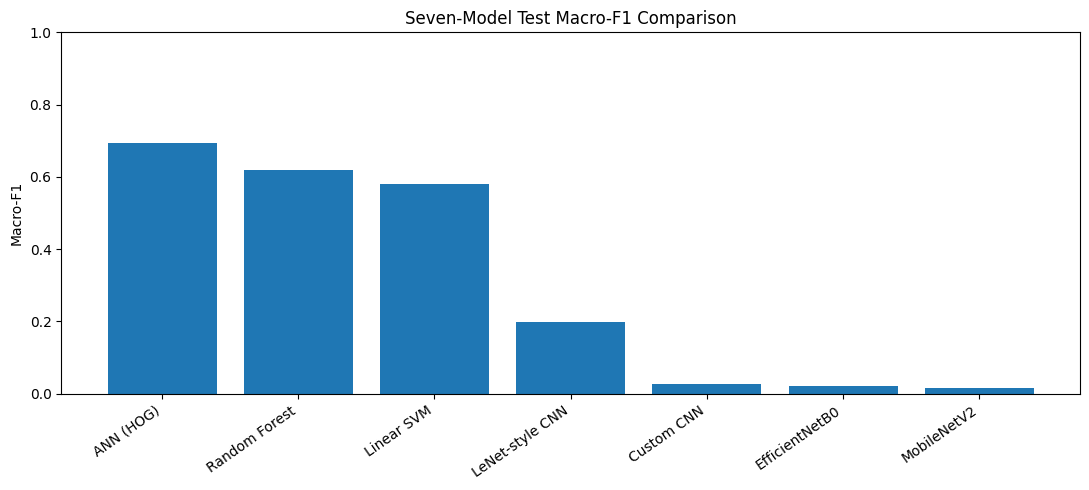

In [29]:
plot_df = comparison_df.sort_values(
    "Macro F1",
    ascending=False,
)

plt.figure(figsize=(11, 5))
plt.bar(
    plot_df["Model"],
    plot_df["Macro F1"],
)
plt.title("Seven-Model Test Macro-F1 Comparison")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 27. Accuracy vs Balanced Accuracy

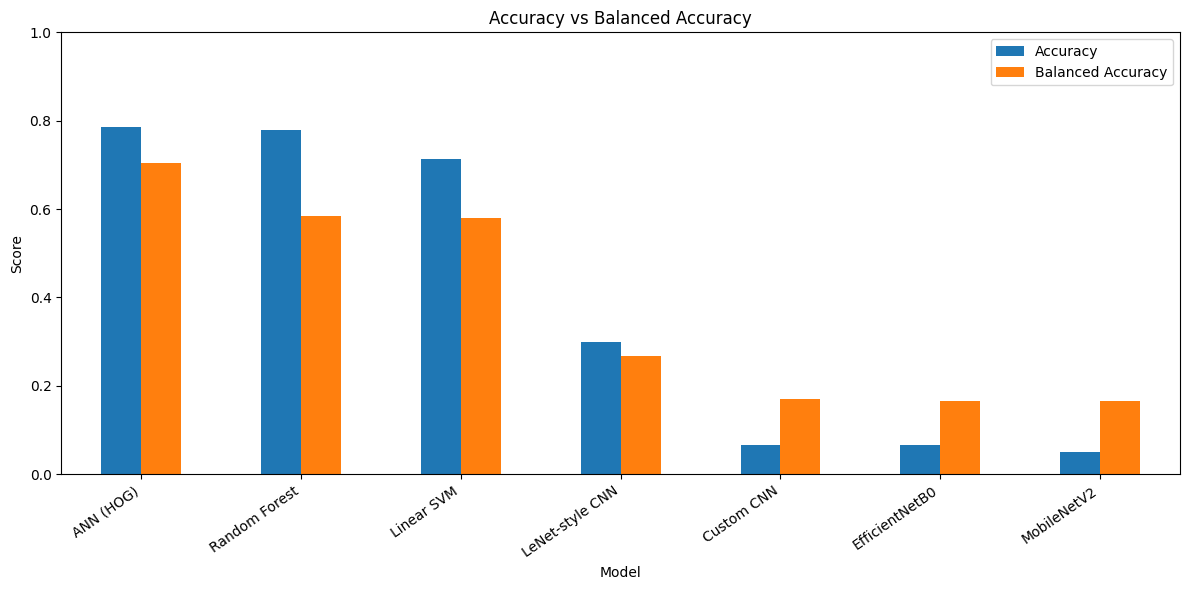

In [30]:
score_df = comparison_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Balanced Accuracy",
    ]
]

score_df.plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title("Accuracy vs Balanced Accuracy")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 28. Training-time comparison

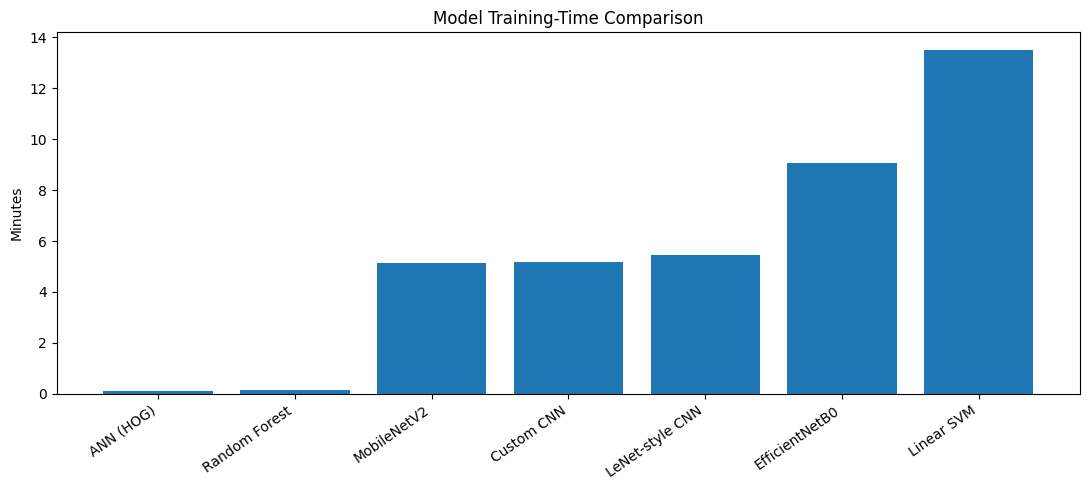

In [31]:
plot_df = comparison_df.sort_values(
    "Training Time (min)",
)

plt.figure(figsize=(11, 5))
plt.bar(
    plot_df["Model"],
    plot_df["Training Time (min)"],
)
plt.title("Model Training-Time Comparison")
plt.ylabel("Minutes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 29. Confusion matrices for SVM, Random Forest and ANN

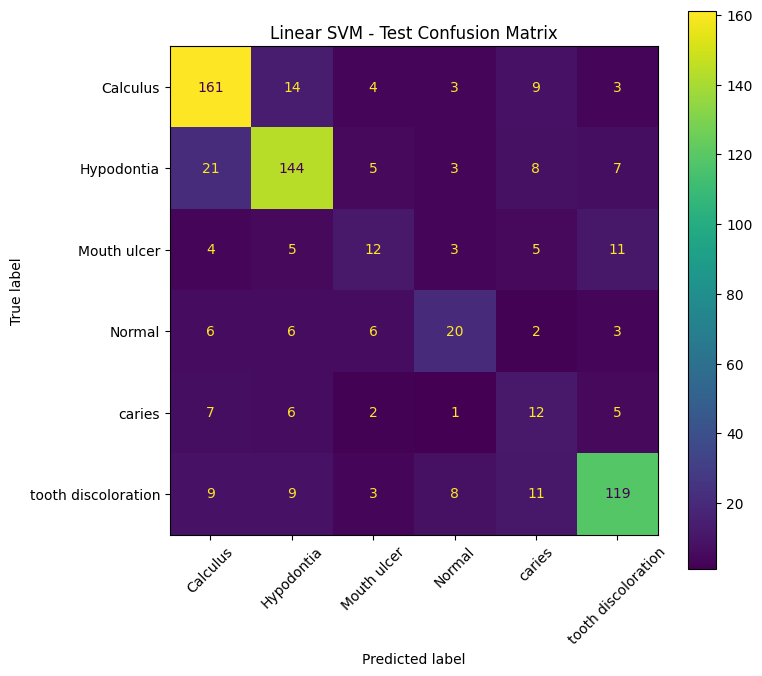

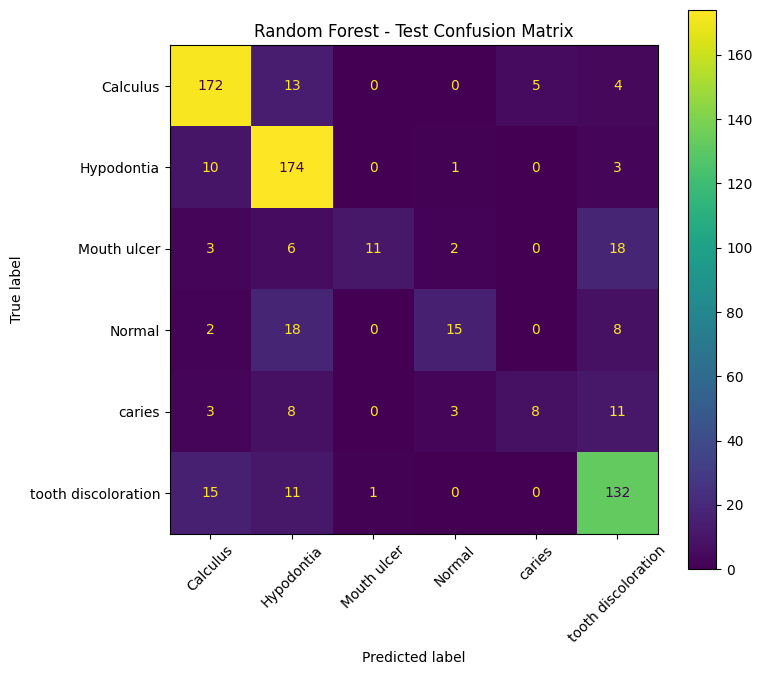

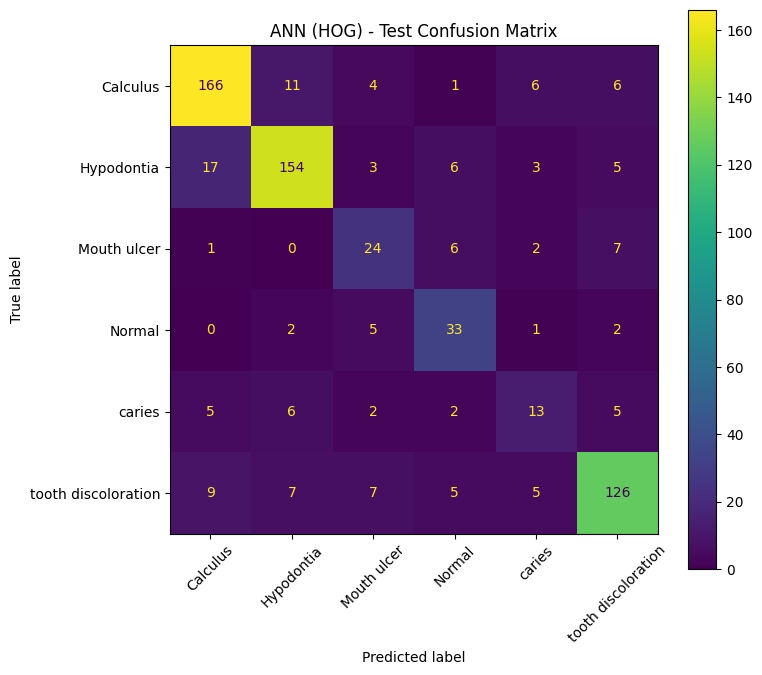

In [32]:
classical_predictions = {
    "Linear SVM": svm_test_pred,
    "Random Forest": rf_test_pred,
    "ANN (HOG)": ann_test_pred,
}

for model_name, preds in classical_predictions.items():

    cm = confusion_matrix(
        y_test,
        preds,
        labels=np.arange(NUM_CLASSES),
    )

    fig, ax = plt.subplots(
        figsize=(8, 7)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )

    disp.plot(
        ax=ax,
        xticks_rotation=45,
        values_format="d",
    )

    plt.title(
        f"{model_name} - Test Confusion Matrix"
    )

    plt.tight_layout()
    plt.show()

## 30. Classification reports for HOG-based models

In [33]:
for name, preds in classical_predictions.items():

    report = classification_report(
        y_test,
        preds,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    report_df = pd.DataFrame(
        report
    ).T

    slug = (
        name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    report_df.to_csv(
        OUTPUT_DIR
        / f"{slug}_classification_report.csv"
    )

    print("\n", name)
    display(report_df)


 Linear SVM


,precision,recall,f1-score,support
Calculus,0.774038,0.829897,0.800995,194.000000
Hypodontia,0.782609,0.765957,0.774194,188.000000
Mouth ulcer,0.375000,0.300000,0.333333,40.000000
Normal,0.526316,0.465116,0.493827,43.000000
caries,0.255319,0.363636,0.300000,33.000000
tooth discoloration,0.804054,0.748428,0.775244,159.000000
accuracy,0.712329,0.712329,0.712329,0.712329
macro avg,0.586223,0.578839,0.579599,657.000000
weighted avg,0.717193,0.712329,0.713353,657.000000



 Random Forest


,precision,recall,f1-score,support
Calculus,0.839024,0.886598,0.862155,194.0000
Hypodontia,0.756522,0.925532,0.832536,188.0000
Mouth ulcer,0.916667,0.275000,0.423077,40.0000
Normal,0.714286,0.348837,0.468750,43.0000
caries,0.615385,0.242424,0.347826,33.0000
tooth discoloration,0.750000,0.830189,0.788060,159.0000
accuracy,0.779300,0.779300,0.779300,0.7793
macro avg,0.765314,0.584763,0.620401,657.0000
weighted avg,0.779202,0.779300,0.757434,657.0000



 ANN (HOG)


,precision,recall,f1-score,support
Calculus,0.838384,0.855670,0.846939,194.000000
Hypodontia,0.855556,0.819149,0.836957,188.000000
Mouth ulcer,0.533333,0.600000,0.564706,40.000000
Normal,0.622642,0.767442,0.687500,43.000000
caries,0.433333,0.393939,0.412698,33.000000
tooth discoloration,0.834437,0.792453,0.812903,159.000000
accuracy,0.785388,0.785388,0.785388,0.785388
macro avg,0.686281,0.704776,0.693617,657.000000
weighted avg,0.789305,0.785388,0.786416,657.000000


## 31. Comparative Evaluation

The final comparison is performed using the validation Macro F1-score for model selection and held-out test metrics for performance reporting. This is particularly important for the present dataset because the class distribution is imbalanced.

The comparative analysis includes:

- Accuracy
- Balanced Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Weighted F1-score
- Training time
- Model parameter count, where applicable

Confusion matrices and class-wise classification reports are also generated to examine per-class predictive behavior.


## Methodological Summary

The experiment compares three modeling strategies:

- **Direct image-based deep learning:** Custom CNN, LeNet-style CNN, MobileNetV2, and EfficientNetB0
- **Handcrafted feature-based classical machine learning:** HOG + Linear SVM and HOG + Random Forest
- **Handcrafted feature-based neural network:** HOG + ANN

This design enables comparison between automatically learned image representations and handcrafted HOG feature representations under a common evaluation framework.